In [1]:
import sys
!{sys.executable} -m pip install -q pandas matplotlib

# 02. Plans through history: what was promised, what happened

This is the long chapter. It compares planning targets with actual outcomes from the first plan in 1953 to the 14th plan, and it judges the big policies honestly, including the failures.

Two ways of reading the numbers are used side by side. Official plan targets come from plan documents and government summaries. Actual outcomes come mostly from the World Bank, an independent series, so the reader can check the official story against outside data. Where the two disagree, both are shown.

## The headline in one paragraph

From 1978 to 2015, China's economy grew about 9.8 percent a year on World Bank data (the People's Daily cites 9.6 percent for the same period, a small vintage difference). GDP per person rose from 157 dollars in 1978 to 13,293 dollars in 2024. Extreme poverty at the World Bank 2.15 dollar line fell from 97.0 percent in 1981 to 0.0 percent in 2019. Life expectancy rose from 63.1 years in 1978 to 78.0 years in 2024 on the World Bank series (the official figure for 2024 is 79.0 years). Those are the achievements. The failures are real too: a famine that killed tens of millions, a decade of political turmoil that shut universities, severe pollution, a debt pile near 300 percent of GDP, a property crash, and a population now shrinking. Both halves belong in the story.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
PROC = "../data/processed"
CHARTS = "../charts"

wb = pd.read_csv(f"{PROC}/wb_longrun.csv")
plans = pd.read_csv(f"{PROC}/plan_history.csv")
g = wb.dropna(subset=["gdp_growth_pct"])
periods = [("1st", 1953, 1957), ("2nd", 1958, 1962), ("3rd", 1966, 1970),
           ("4th", 1971, 1975), ("5th", 1976, 1980), ("6th", 1981, 1985),
           ("7th", 1986, 1990), ("8th", 1991, 1995), ("9th", 1996, 2000),
           ("10th", 2001, 2005), ("11th", 2006, 2010), ("12th", 2011, 2015),
           ("13th", 2016, 2020), ("14th", 2021, 2025)]
rows = []
for name, a, b in periods:
    sub = g[(g.year >= a) & (g.year <= b)]
    rows.append([name, f"{a}-{b}", round(sub.gdp_growth_pct.mean(), 2)
                 if len(sub) else None, len(sub)])
era = pd.DataFrame(rows, columns=["plan", "years", "avg_gdp_growth_pct_wb", "years_with_data"])
print(era.to_string(index=False))
print()
print("Note: the World Bank growth series starts in 1961, so the 1st and 2nd plan rows use fewer years.")


plan     years  avg_gdp_growth_pct_wb  years_with_data
 1st 1953-1957                    NaN                0
 2nd 1958-1962                 -16.42                2
 3rd 1966-1970                   7.40                5
 4th 1971-1975                   5.93                5
 5th 1976-1980                   6.55                5
 6th 1981-1985                  10.71                5
 7th 1986-1990                   7.99                5
 8th 1991-1995                  12.34                5
 9th 1996-2000                   8.70                5
10th 2001-2005                   9.85                5
11th 2006-2010                  11.30                5
12th 2011-2015                   7.91                5
13th 2016-2020                   5.77                5
14th 2021-2025                   5.41                5

Note: the World Bank growth series starts in 1961, so the 1st and 2nd plan rows use fewer years.


## How to read the era table

The 2nd plan row is deeply negative, minus 16.4 percent on average, but it only covers 1961 and 1962, because the World Bank growth series starts in 1961. Those were the famine collapse years, so the row shows the disaster, not the whole plan. The 1st plan row is blank for the same reason: no World Bank growth data exists for 1953 to 1957. Averages also hide disasters in the other direction. The 1966 to 1976 period is not one row in the table, but computed separately it averages about 5.9 percent a year, which looks ordinary while hiding school closures and political turmoil.

From the 6th plan onward, every five year block averaged between about 5.4 and 12.3 percent growth. The reform era is the long boom. It slowed step by step: about 11.3 percent in the 11th plan, 7.9 percent in the 12th, 5.8 percent in the 13th, and 5.4 percent in the 14th.

1960 GDP, billion USD: 59.8
1978 GDP, billion USD: 149.8
2024 GDP, billion USD: 18729.7
saved 02_gdp_log.png


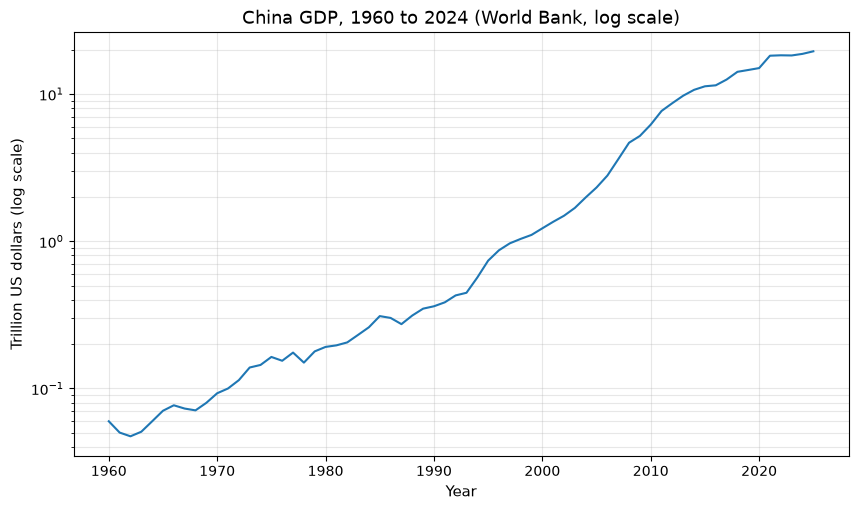

In [3]:

fig, ax = plt.subplots()
wb2 = wb.dropna(subset=["gdp_usd"])
ax.plot(wb2.year, wb2.gdp_usd / 1e12)
ax.set_yscale("log")
ax.set_ylabel("Trillion US dollars (log scale)")
ax.set_xlabel("Year")
ax.set_title("China GDP, 1960 to 2024 (World Bank, log scale)")
ax.grid(True, which="both", alpha=0.3)
plt.savefig(f"{CHARTS}/02_gdp_log.png", dpi=150, bbox_inches="tight")
print("1960 GDP, billion USD:", round(wb2[wb2.year == 1960].gdp_usd.iloc[0] / 1e9, 1))
print("1978 GDP, billion USD:", round(wb2[wb2.year == 1978].gdp_usd.iloc[0] / 1e9, 1))
print("2024 GDP, billion USD:", round(wb2[wb2.year == 2024].gdp_usd.iloc[0] / 1e9, 1))
print("saved 02_gdp_log.png")


GDP per person 1978: 156.7
GDP per person 2024: 13293.1
saved 02_gdp_per_capita.png


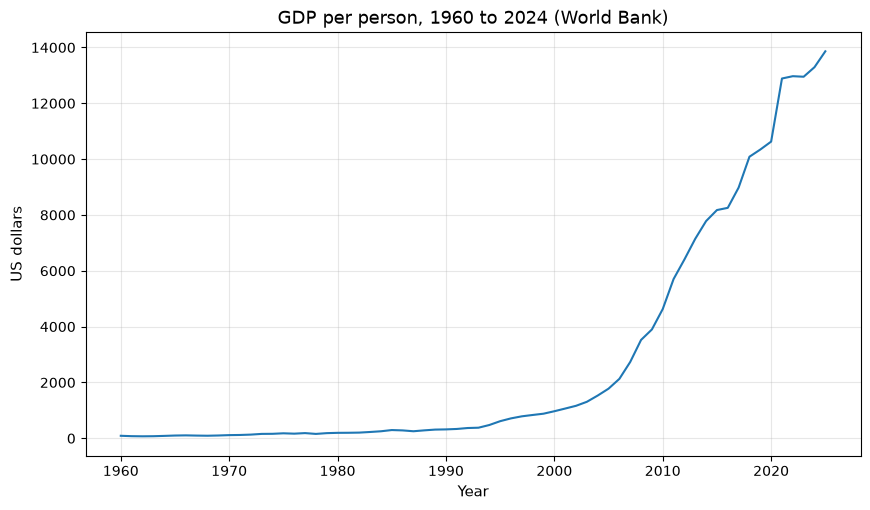

In [4]:

fig, ax = plt.subplots()
wb3 = wb.dropna(subset=["gdp_per_capita_usd"])
ax.plot(wb3.year, wb3.gdp_per_capita_usd)
ax.set_ylabel("US dollars")
ax.set_xlabel("Year")
ax.set_title("GDP per person, 1960 to 2024 (World Bank)")
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_gdp_per_capita.png", dpi=150, bbox_inches="tight")
print("GDP per person 1978:", round(wb3[wb3.year == 1978].gdp_per_capita_usd.iloc[0], 1))
print("GDP per person 2024:", round(wb3[wb3.year == 2024].gdp_per_capita_usd.iloc[0], 1))
print("saved 02_gdp_per_capita.png")


saved 02_growth_by_plan.png


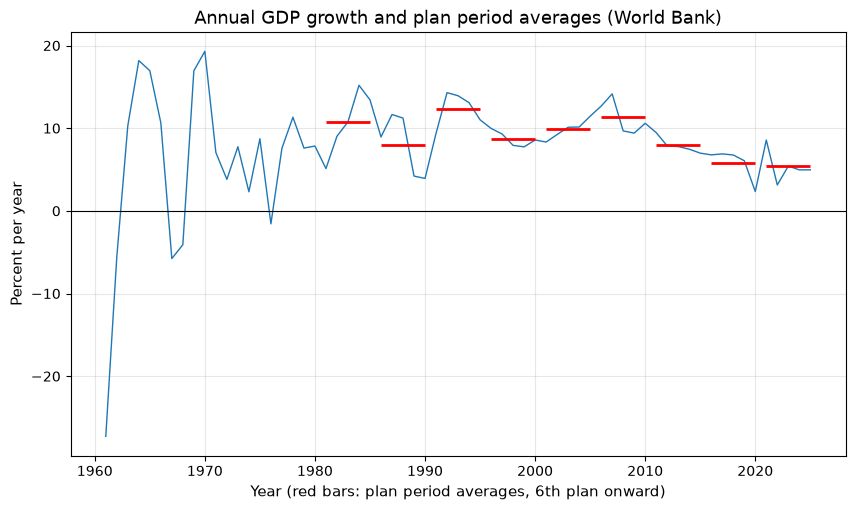

In [5]:

fig, ax = plt.subplots()
ax.plot(g.year, g.gdp_growth_pct, linewidth=1)
for name, a, b in periods[5:]:
    sub = g[(g.year >= a) & (g.year <= b)]
    ax.hlines(sub.gdp_growth_pct.mean(), a, b, colors="red", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Percent per year")
ax.set_xlabel("Year (red bars: plan period averages, 6th plan onward)")
ax.set_title("Annual GDP growth and plan period averages (World Bank)")
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_growth_by_plan.png", dpi=150, bbox_inches="tight")
print("saved 02_growth_by_plan.png")


## Plan targets versus actuals: the verified table

The table below lists the plans where a numeric target could be verified against a stated source. Early plans did not publish the kind of numeric targets modern plans do, so they are described in words. The pattern to notice: growth targets were usually beaten in the boom years (the 11th plan targeted 7.5 percent and got about 11.2 to 11.3 percent), then missed when growth slowed (the 13th plan targeted at least 6.5 percent and got about 5.8 percent). Energy targets show the opposite pattern in recent plans: the 11th plan missed its 20 percent energy saving goal by a fraction (19.1 percent), the 12th beat its 16 percent goal (18.2 percent), and the 13th missed its 15 percent goal (about 13.8 percent) while beating its carbon goal (about 22 percent against 18 percent).

In [6]:

print(plans[["plan", "years", "gdp_growth_target", "energy_intensity_target",
             "carbon_intensity_target"]].to_string(index=False))


plan     years    gdp_growth_target energy_intensity_target carbon_intensity_target
 1st 1953-1957                  NaN                     NaN                     NaN
 2nd 1958-1962                  NaN                     NaN                     NaN
 3rd 1966-1970                  NaN                     NaN                     NaN
 4th 1971-1975                  NaN                     NaN                     NaN
 5th 1976-1980                  NaN                     NaN                     NaN
 6th 1981-1985                  NaN                     NaN                     NaN
 7th 1986-1990                  NaN                     NaN                     NaN
 8th 1991-1995                  NaN                     NaN                     NaN
 9th 1996-2000                  NaN                     NaN                     NaN
10th 2001-2005      about 7% a year                     NaN                     NaN
11th 2006-2010          7.5% a year                    -20%                 

## Poverty: the strongest result, on two different yardsticks

Two poverty series are often confused. They measure different things, and both are shown.

- The World Bank line of 2.15 dollars a day (2017 prices) is an international extreme poverty line. On it, China went from 97.0 percent of the population in 1981 to 83.1 percent in 1990, 20.6 percent in 2010, and 0.0 percent in 2019. That is the largest poverty reduction ever recorded on one consistent yardstick.
- China's own rural poverty line is a national standard, lower than the World Bank line in income terms for much of the period. On it, the official count of rural poor fell from 770 million at the end of 1978 to 98.99 million in 2012, a rate of 97.5 percent down to 10.2 percent. The targeted campaign then lifted the remaining 98.99 million by the end of 2020, covering 832 counties and 128,000 villages, with about 1.6 trillion yuan in special funds.

The honest caveat: the national line was low, so clearing it did not mean a comfortable life. And officials themselves set up a transition period after 2020 to stop people sliding back, which shows the result needed defending.

poverty 1981: 97.0
poverty 2019: 0.0
saved 02_poverty.png


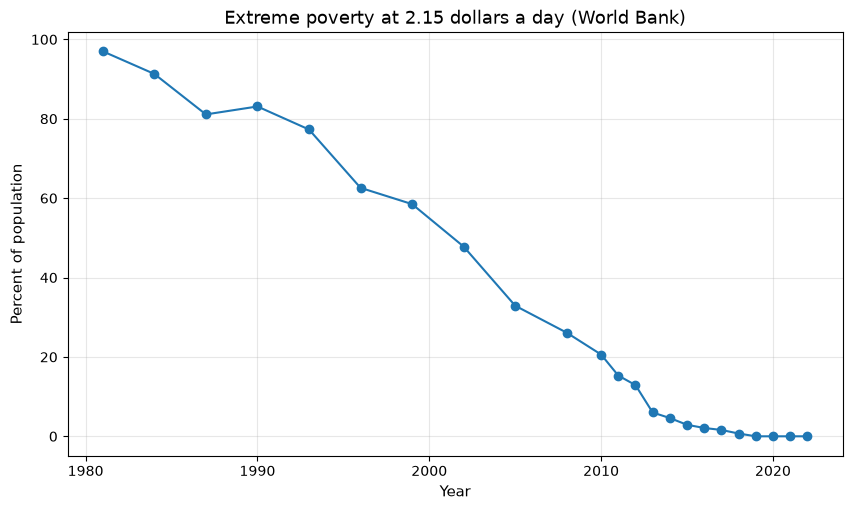

In [7]:

fig, ax = plt.subplots()
pov = wb.dropna(subset=["poverty_215_pct"])
ax.plot(pov.year, pov.poverty_215_pct, marker="o")
ax.set_ylabel("Percent of population")
ax.set_xlabel("Year")
ax.set_title("Extreme poverty at 2.15 dollars a day (World Bank)")
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_poverty.png", dpi=150, bbox_inches="tight")
print("poverty 1981:", pov[pov.year == 1981].poverty_215_pct.iloc[0])
print("poverty 2019:", pov[pov.year == 2019].poverty_215_pct.iloc[0])
print("saved 02_poverty.png")


life expectancy 1960: 33.419
life expectancy 1978: 63.102
life expectancy 2024: 78.017
saved 02_life_expectancy.png


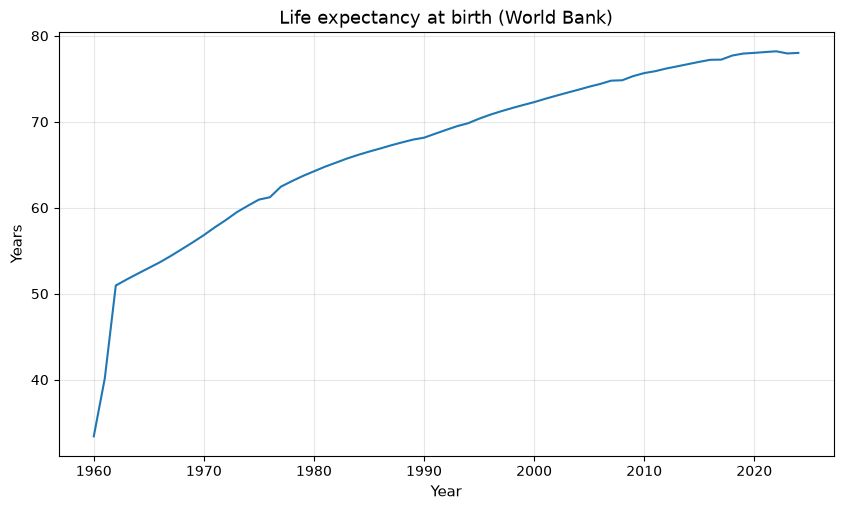

In [8]:

fig, ax = plt.subplots()
le = wb.dropna(subset=["life_expectancy"])
ax.plot(le.year, le.life_expectancy)
ax.set_ylabel("Years")
ax.set_xlabel("Year")
ax.set_title("Life expectancy at birth (World Bank)")
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_life_expectancy.png", dpi=150, bbox_inches="tight")
print("life expectancy 1960:", le[le.year == 1960].life_expectancy.iloc[0])
print("life expectancy 1978:", le[le.year == 1978].life_expectancy.iloc[0])
print("life expectancy 2024:", le[le.year == 2024].life_expectancy.iloc[0])
print("saved 02_life_expectancy.png")


## Health and cities

Life expectancy tells a story the GDP chart hides. It collapsed to 33.4 years in 1960 in the famine, then recovered fast, reaching 63.1 years by 1978 and 78.0 years by 2024 on the World Bank series. The official figure for 2024 is 79.0 years. The gap between the two series is a reminder to always ask which series a number comes from.

Urbanization moved with the economy. The World Bank series puts the urban share at 17.9 percent in 1978, 36.4 percent in 2000, and 65.9 percent in 2024. The NBS permanent resident rate for 2025 is 67.89 percent. Hundreds of millions of people moved to cities, the largest migration in history, and the hukou system still limits many migrants' access to city schools, health care, and pensions.

The population is now aging fast. The share aged 65 and over rose from 4.2 percent in 1978 to 7.0 percent in 2000 and 14.7 percent in 2024. Fertility fell from 6.09 children per woman in 1970 to 2.72 in 1978, 1.63 in 2000, and about 1.0 in 2023 and 2024.

saved 02_urban_aging.png


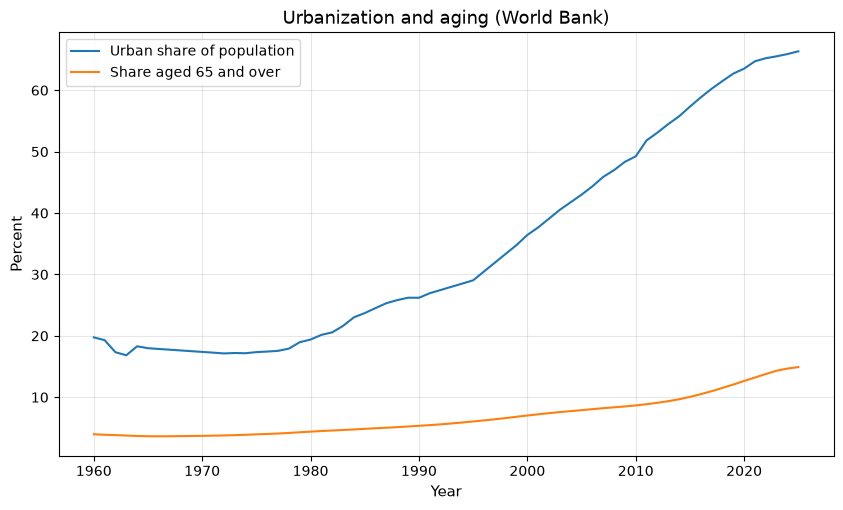

In [9]:

fig, ax = plt.subplots()
u = wb.dropna(subset=["urban_pct", "pop_65_pct"])
ax.plot(u.year, u.urban_pct, label="Urban share of population")
ax.plot(u.year, u.pop_65_pct, label="Share aged 65 and over")
ax.set_ylabel("Percent")
ax.set_xlabel("Year")
ax.set_title("Urbanization and aging (World Bank)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_urban_aging.png", dpi=150, bbox_inches="tight")
print("saved 02_urban_aging.png")


exports peak: 2006.0 35.5 percent of GDP
exports 2024: 20.4
saved 02_trade.png


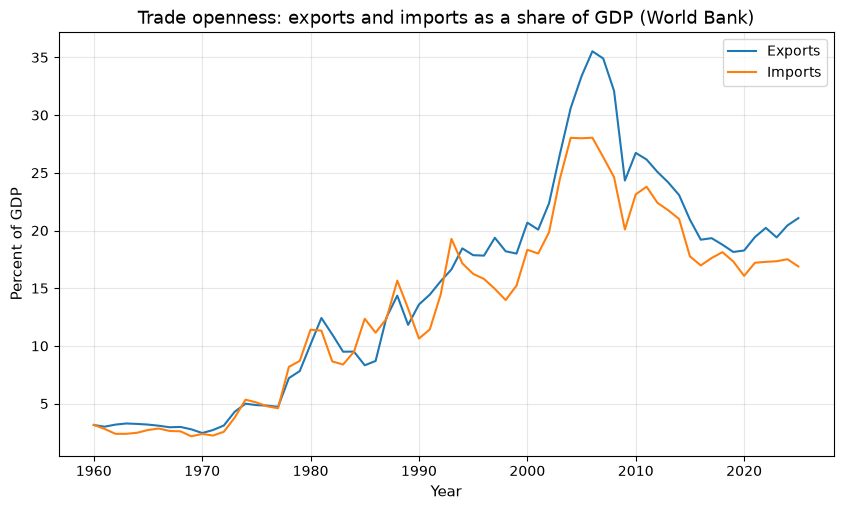

In [10]:

fig, ax = plt.subplots()
t = wb.dropna(subset=["exports_pct_gdp", "imports_pct_gdp"])
ax.plot(t.year, t.exports_pct_gdp, label="Exports")
ax.plot(t.year, t.imports_pct_gdp, label="Imports")
ax.set_ylabel("Percent of GDP")
ax.set_xlabel("Year")
ax.set_title("Trade openness: exports and imports as a share of GDP (World Bank)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(f"{CHARTS}/02_trade.png", dpi=150, bbox_inches="tight")
peak = t.loc[t.exports_pct_gdp.idxmax()]
print("exports peak:", peak.year, round(peak.exports_pct_gdp, 1), "percent of GDP")
print("exports 2024:", round(t[t.year == 2024].exports_pct_gdp.iloc[0], 1))
print("saved 02_trade.png")


## Policies: what each one aimed at, what the data shows, and the verdict

Verdict words used here: worked (aim broadly achieved), mixed (real gains with real costs or partial success), missed (aim not achieved), reversed (policy later undone by its own makers), too early (not enough time to judge).

### Reform and Opening, from December 1978. Aim: grow the economy by letting markets work inside a state led system. Evidence: growth averaged about 9.8 percent a year from 1978 to 2015 (World Bank). Verdict: worked on growth. Costs: inequality rose, corruption grew, and the environment paid a high price.

### Household responsibility system, 1978 to 1984. Aim: give farm families a reason to produce more by letting them keep output above a quota. Evidence: grain output rose from 304.8 million tons in 1978 to 407.3 million tons in 1984, up 33.6 percent, and farm income more than doubled. Verdict: worked.

### Special Economic Zones, from 1980. Aim: test markets in small coastal areas before rolling them out. Evidence: the first four zones were Shenzhen, Zhuhai, Shantou, and Xiamen. Shenzhen grew about 54 percent a year from 1980 to 1984, and the four zones took 26 percent of China's foreign investment in 1984. Verdict: worked as an experiment. Cost: coastal regions pulled far ahead of inland ones.

### Dual-track pricing, from 1984. Aim: move toward market prices without a sudden shock, by keeping a low plan price and letting extra output sell at a market price. Evidence: prices were mostly freed by the 1990s without the output collapse seen in Russia's shock therapy. Cost: the gap between plan and market prices created arbitrage and corruption. Verdict: mixed.

### Township and village enterprises, 1980s to 1990s. Aim: let rural industry absorb farm labor. Evidence: rural enterprises grew fast through the 1980s and employed well over 100 million people by the mid 1990s on commonly cited figures. Many were later privatized or closed in the late 1990s shakeout. Verdict: mixed. They filled a gap, then faded.

### State-owned enterprise reform, late 1990s. Aim: make big state firms profitable by cutting losses and shedding workers. Evidence: large state firms became more profitable, but layoffs ran into the tens of millions, often cited at around 30 million. The safety net at the time was thin. Verdict: mixed. Efficiency up, social cost high.

### WTO accession, December 2001. Aim: lock in export markets and force domestic firms to compete. Evidence: exports rose to a peak of 35.5 percent of GDP in 2006 (World Bank), and China became the world's largest exporter. Verdict: worked on trade. The adjustment costs for workers in import hit sectors, at home and abroad, are still debated.

### The 2008 stimulus. Aim: protect growth when the global financial crisis crushed exports. Evidence: the government announced a 4 trillion yuan package in November 2008, and growth rebounded to 10.6 percent in 2010 (World Bank). Cost: debt ballooned, and much of the money fed a property and infrastructure boom that later turned into overcapacity and bad loans. Verdict: mixed.

### Supply-side reform, from 2015. Aim: cut overcapacity in steel and coal, reduce housing inventory, and lower business costs. Evidence: capacity was cut in steel and coal, but debt and property risks stayed high and later got worse. Verdict: mixed. Direction changed, problems persisted.

### Targeted poverty alleviation, 2013 to 2020. Aim: lift every remaining rural poor person under the national line by the end of 2020. Evidence: 98.99 million people, 832 counties, and 128,000 villages were lifted on official counts, with about 1.6 trillion yuan in special funds. Verdict: worked on its own standard. Caveats: the line was low, and the government set up a five year transition after 2020 to stop people sliding back.

### One-child policy and its reversals. Aim: slow population growth. Evidence: fertility fell from 6.09 in 1970 to about 1.0 in 2023 and 2024, and the population has shrunk every year since 2022. The policy was replaced by a two-child limit in 2016 and a three-child limit in 2021, yet births kept falling, from 17.86 million in 2016 to 7.92 million in 2025. Verdict: reversed. It achieved slower growth, then overshot so far that the government now pays families to have children.

### Dual circulation, from 2020. Aim: rely more on domestic demand while staying open to the world, and reduce dependence on foreign technology. Evidence: mixed so far. Final consumption contributed 52 percent of 2025 growth, up 5 points on 2024, but the trade surplus was still about 1 trillion dollars in 2024. Verdict: too early, and the data pulls both ways.

### Common prosperity, from 2021. Aim: narrow inequality and share growth more widely. Evidence: the urban to rural income ratio narrowed slightly, to 2.31 in 2025, down 0.03 on 2024. A full inequality verdict needs a recent income distribution series, which this build did not fetch, so that part is a documented cut. Verdict: too early.

### Tech self-reliance, including Made in China 2025. Aim: lead in advanced manufacturing and cut dependence on foreign chips and equipment. Evidence: research spending reached about 3.93 trillion yuan in 2025, 2.80 percent of GDP, above the OECD average of 2.72 percent for the first time, and high-value patents hit 16 per 10,000 people. But the 70 percent chip self-sufficiency goal in Made in China 2025 is described in secondary analysis as largely missed, and the 15th plan drops that goal. Verdict: mixed. Strong in research inputs and some sectors, weak in advanced chips.

## The failures, stated plainly

### The Great Leap Forward and the famine, 1958 to 1962

The 2nd plan aimed to leap ahead in heavy industry. Millions of farm workers were moved into backyard steel furnaces and big projects, officials under pressure to meet quotas reported grain that did not exist, and the state kept taking grain while villages starved. Grain output fell more than 25 percent in 1960 to 1961.

How many died is contested, and this project does not pick one number. Government statistics imply about 15 million excess deaths. Scholarly estimates range from 15 million to 46 million, with newer estimates concentrated between 30 million and 46 million. Named estimates: about 30 million (Ashton and co-authors, 1984, demographic reconstruction), 32.5 million (Cao Shuji, county records), 36 million (Yang Jisheng, Tombstone, from internal records), and at least 45 million (Frank Dikotter, Mao's Great Famine, from provincial archives, a figure other scholars have questioned). The hardest hit provinces, by share of population dead, were Anhui (18 percent), Chongqing (15 percent), Sichuan (13 percent), Guizhou (11 percent), and Hunan (8 percent).

### The Cultural Revolution, 1966 to 1976

A political campaign, not an economic plan, but it wrecked a decade of development. Universities closed, the university entrance exam was suspended from 1966 until it was restored in 1977, and a generation lost schooling. Growth averaged about 5.9 percent a year across 1966 to 1976 on World Bank data, but it swung sharply and the country fell behind its East Asian neighbors.

### Environmental costs

Growth was bought with coal. Energy use per person rose from 773 kilograms of oil equivalent in 1990 to 2,947 in 2024 (World Bank). Coal still supplied 51.4 percent of energy consumption in 2025, though that was down 1.8 points on 2024. Air pollution has improved a lot since the worst years: average PM2.5 was 28 micrograms per cubic meter in 2025, down 20 percent over five years. The cleanup is real, but it started from very dirty air, and China is still the world's largest carbon emitter in total, even as its emissions per unit of GDP fall.

### Overcapacity, debt, and the property crash

The investment led model produced too much of some things: steel, coal, housing, and now solar panels and electric vehicles. In solar panels, Chinese firms account for nearly 90 percent of global capital investment, per Bruegel analysis. Debt piled up with it. Total non-financial debt reached 296 percent of GDP in the third quarter of 2025 (Congressional Research Service summary of the data), and the IMF put explicit local government debt at 39 percent of GDP plus local financing vehicle debt at 51 percent of GDP in 2025. Property, long about a quarter to a third of GDP including related industries, crashed after 2021: the value of property sales fell 54 percent from 2021, Evergrande defaulted in 2021 on 305 billion dollars of debt, was ordered into liquidation in 2024, and was delisted in August 2025.

### Demographic headwinds

The chart below is the other side of the one-child story. Births fell from 17.86 million in 2016 to 7.92 million in 2025, the first year below 8 million since 1949. The population fell for a fourth straight year in 2025, down 3.39 million to 1,404.89 million. The working-age share is shrinking, which makes the 15th plan's growth math harder, as notebook 06 explains.

births 2016: 17.86
births 2025: 7.92
saved 02_births.png


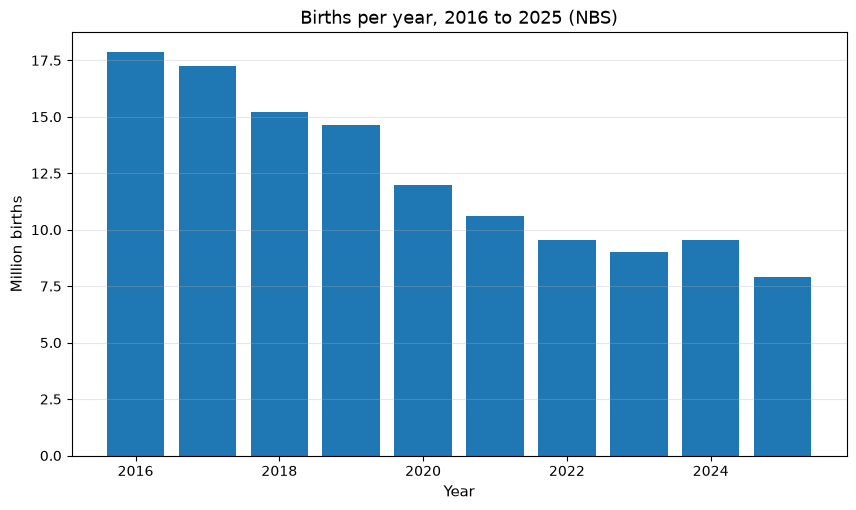

In [11]:

births = pd.read_csv(f"{PROC}/births.csv")
fig, ax = plt.subplots()
ax.bar(births.year, births.births_million)
ax.set_ylabel("Million births")
ax.set_xlabel("Year")
ax.set_title("Births per year, 2016 to 2025 (NBS)")
ax.grid(True, axis="y", alpha=0.3)
plt.savefig(f"{CHARTS}/02_births.png", dpi=150, bbox_inches="tight")
print("births 2016:", births[births.year == 2016].births_million.iloc[0])
print("births 2025:", births[births.year == 2025].births_million.iloc[0])
print("saved 02_births.png")


## Bottom line of the history chapter

Planning did not cause the boom by itself. The boom came when planning loosened: farm families kept their surplus, coastal zones tested markets, and foreign trade was opened. Planning helped most when it set a direction and then let experiment happen, and it failed worst when it set impossible physical targets and punished honest reporting, as in 1958 to 1962. The recent plans are more honest about limits: no GDP number in the 14th plan, binding targets for the environment, and a 15th plan that talks about quality of life as much as speed. Whether that honesty survives slower growth is the question notebook 06 leaves open.

Next: notebook 03 scores the 14th plan, target by target.